 Importing Required Libraries

In [252]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

 Loading the Student Depression Dataset

In [253]:
data = pd.read_csv(r"C:\Users\91949\Downloads\Student Depression Dataset.csv")

df = pd.DataFrame(data)

print(df.head())

   id  Gender   Age           City Profession  Academic Pressure  \
0   2    Male  33.0  Visakhapatnam    Student                5.0   
1   8  Female  24.0      Bangalore    Student                2.0   
2  26    Male  31.0       Srinagar    Student                3.0   
3  30  Female  28.0       Varanasi    Student                3.0   
4  32  Female  25.0         Jaipur    Student                4.0   

   Work Pressure  CGPA  Study Satisfaction  Job Satisfaction  \
0            0.0  8.97                 2.0               0.0   
1            0.0  5.90                 5.0               0.0   
2            0.0  7.03                 5.0               0.0   
3            0.0  5.59                 2.0               0.0   
4            0.0  8.13                 3.0               0.0   

      Sleep Duration Dietary Habits   Degree  \
0          5-6 hours        Healthy  B.Pharm   
1          5-6 hours       Moderate      BSc   
2  Less than 5 hours        Healthy       BA   
3          7-8

Understanding the Dataset

In [254]:
print("Dataset Information:")
print(df.info())

print("\nDataset Description:")
print(df.describe())

print("\nDataset Shape:")
print(df.shape)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  str    
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  str    
 4   Profession                             27901 non-null  str    
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  str  

Checking Missing Values

In [255]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

print("\nTotal Missing Values:")

print(df.isnull().sum().sum())

Missing Values in Each Column:
id                                       0
Gender                                   0
Age                                      0
City                                     0
Profession                               0
Academic Pressure                        0
Work Pressure                            0
CGPA                                     0
Study Satisfaction                       0
Job Satisfaction                         0
Sleep Duration                           0
Dietary Habits                           0
Degree                                   0
Have you ever had suicidal thoughts ?    0
Work/Study Hours                         0
Financial Stress                         3
Family History of Mental Illness         0
Depression                               0
dtype: int64

Total Missing Values:
3


Checking Duplicate Records

In [256]:
print("Total Duplicate Records:")

print(df.duplicated().sum())

Total Duplicate Records:
0


Data Cleaning – Removing Missing Values

In [257]:
df = df.dropna()

print("Dataset after removing missing values:")

print(df.shape)

print("\nMissing Values After Cleaning:")

print(df.isnull().sum().sum())

Dataset after removing missing values:
(27898, 18)

Missing Values After Cleaning:
0


Saving the Cleaned Dataset

In [258]:
df.to_csv("cleaned_student_data.csv", index=False)
print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


Inspecting Categorical Data

In [259]:
print("Gender Values:")
print(df["Gender"].value_counts())

print("\nProfession Values:")
print(df["Profession"].value_counts())

print("\nSleep Duration Values:")
print(df["Sleep Duration"].value_counts())

print("\nDietary Habits Values:")
print(df["Dietary Habits"].value_counts())

print("\nDegree Values:")
print(df["Degree"].value_counts())

Gender Values:
Gender
Male      15546
Female    12352
Name: count, dtype: int64

Profession Values:
Profession
Student                   27867
Architect                     8
Teacher                       6
Digital Marketer              3
Content Writer                2
Chef                          2
Doctor                        2
Pharmacist                    2
Civil Engineer                1
UX/UI Designer                1
Educational Consultant        1
Manager                       1
Lawyer                        1
Entrepreneur                  1
Name: count, dtype: int64

Sleep Duration Values:
Sleep Duration
Less than 5 hours    8309
7-8 hours            7346
5-6 hours            6181
More than 8 hours    6044
Others                 18
Name: count, dtype: int64

Dietary Habits Values:
Dietary Habits
Unhealthy    10316
Moderate      9921
Healthy       7649
Others          12
Name: count, dtype: int64

Degree Values:
Degree
Class 12    6080
B.Ed        1866
B.Com       1506
B.Arc

Cleaning Categorical Values

Cleaning Categorical Values

In [260]:
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].str.strip()

print("Extra spaces removed from categorical columns.")

print(df.head())

Extra spaces removed from categorical columns.
   id  Gender   Age           City Profession  Academic Pressure  \
0   2    Male  33.0  Visakhapatnam    Student                5.0   
1   8  Female  24.0      Bangalore    Student                2.0   
2  26    Male  31.0       Srinagar    Student                3.0   
3  30  Female  28.0       Varanasi    Student                3.0   
4  32  Female  25.0         Jaipur    Student                4.0   

   Work Pressure  CGPA  Study Satisfaction  Job Satisfaction  \
0            0.0  8.97                 2.0               0.0   
1            0.0  5.90                 5.0               0.0   
2            0.0  7.03                 5.0               0.0   
3            0.0  5.59                 2.0               0.0   
4            0.0  8.13                 3.0               0.0   

      Sleep Duration Dietary Habits   Degree  \
0          5-6 hours        Healthy  B.Pharm   
1          5-6 hours       Moderate      BSc   
2  Less than 5 

C:\Users\91949\AppData\Local\Temp\ipykernel_14568\1583394845.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


Checking Numerical Columns

In [261]:
num_cols = df.select_dtypes(include=["int64", "float64"]).columns

print("Numerical Columns:")

for col in num_cols:
    print("\nColumn:", col)
    print("Minimum Value:", df[col].min())
    print("Maximum Value:", df[col].max())

Numerical Columns:

Column: id
Minimum Value: 2
Maximum Value: 140699

Column: Age
Minimum Value: 18.0
Maximum Value: 59.0

Column: Academic Pressure
Minimum Value: 0.0
Maximum Value: 5.0

Column: Work Pressure
Minimum Value: 0.0
Maximum Value: 5.0

Column: CGPA
Minimum Value: 0.0
Maximum Value: 10.0

Column: Study Satisfaction
Minimum Value: 0.0
Maximum Value: 5.0

Column: Job Satisfaction
Minimum Value: 0.0
Maximum Value: 4.0

Column: Work/Study Hours
Minimum Value: 0.0
Maximum Value: 12.0

Column: Financial Stress
Minimum Value: 1.0
Maximum Value: 5.0

Column: Depression
Minimum Value: 0
Maximum Value: 1


Statistical Analysis of Important Features

In [262]:
print("Academic Pressure:")
print(df["Academic Pressure"].value_counts().sort_index())

print("\nStudy Satisfaction:")
print(df["Study Satisfaction"].value_counts().sort_index())

print("\nFinancial Stress:")
print(df["Financial Stress"].value_counts().sort_index())

print("\nCGPA:")
print(df["CGPA"].describe())

print("\nAge:")
print(df["Age"].describe())

Academic Pressure:
Academic Pressure
0.0       9
1.0    4800
2.0    4177
3.0    7461
4.0    5155
5.0    6296
Name: count, dtype: int64

Study Satisfaction:
Study Satisfaction
0.0      10
1.0    5449
2.0    5838
3.0    5820
4.0    6359
5.0    4422
Name: count, dtype: int64

Financial Stress:
Financial Stress
1.0    5121
2.0    5061
3.0    5226
4.0    5775
5.0    6715
Name: count, dtype: int64

CGPA:
count    27898.000000
mean         7.656160
std          1.470708
min          0.000000
25%          6.290000
50%          7.770000
75%          8.920000
max         10.000000
Name: CGPA, dtype: float64

Age:
count    27898.000000
mean        25.822174
std          4.905651
min         18.000000
25%         21.000000
50%         25.000000
75%         30.000000
max         59.000000
Name: Age, dtype: float64


Analyzing Profession Distribution

In [263]:
print("Profession Distribution:")

print(df["Profession"].value_counts())

Profession Distribution:
Profession
Student                   27867
Architect                     8
Teacher                       6
Digital Marketer              3
Content Writer                2
Chef                          2
Doctor                        2
Pharmacist                    2
Civil Engineer                1
UX/UI Designer                1
Educational Consultant        1
Manager                       1
Lawyer                        1
Entrepreneur                  1
Name: count, dtype: int64


Selecting Student Records

In [264]:
student_df = df[df["Profession"] == "Student"].copy()

print("Student Dataset Shape:")

print(student_df.shape)

print("\nProfession Distribution:")

print(student_df["Profession"].value_counts())

Student Dataset Shape:
(27867, 18)

Profession Distribution:
Profession
Student    27867
Name: count, dtype: int64


Removing Unnecessary Columns

In [265]:
student_df.drop(
    columns=["id", "Profession", "Work Pressure", "Job Satisfaction"],
    inplace=True
)

print("Unnecessary columns removed.")

print(student_df.info())

print("\nUpdated Dataset Shape:")

print(student_df.shape)

Unnecessary columns removed.
<class 'pandas.DataFrame'>
Index: 27867 entries, 0 to 27900
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 27867 non-null  str    
 1   Age                                    27867 non-null  float64
 2   City                                   27867 non-null  str    
 3   Academic Pressure                      27867 non-null  float64
 4   CGPA                                   27867 non-null  float64
 5   Study Satisfaction                     27867 non-null  float64
 6   Sleep Duration                         27867 non-null  str    
 7   Dietary Habits                         27867 non-null  str    
 8   Degree                                 27867 non-null  str    
 9   Have you ever had suicidal thoughts ?  27867 non-null  str    
 10  Work/Study Hours                       27867 non-null  fl

Final Dataset Verification

In [266]:
print("Final Dataset Information:")

print(student_df.info())

print("\nMissing Values:")

print(student_df.isnull().sum())

print("\nDuplicate Records:")

print(student_df.duplicated().sum())

print("\nFirst Five Records:")

print(student_df.head())

Final Dataset Information:
<class 'pandas.DataFrame'>
Index: 27867 entries, 0 to 27900
Data columns (total 14 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 27867 non-null  str    
 1   Age                                    27867 non-null  float64
 2   City                                   27867 non-null  str    
 3   Academic Pressure                      27867 non-null  float64
 4   CGPA                                   27867 non-null  float64
 5   Study Satisfaction                     27867 non-null  float64
 6   Sleep Duration                         27867 non-null  str    
 7   Dietary Habits                         27867 non-null  str    
 8   Degree                                 27867 non-null  str    
 9   Have you ever had suicidal thoughts ?  27867 non-null  str    
 10  Work/Study Hours                       27867 non-null  floa

Saving the Student Dataset

In [267]:
student_df.to_csv(
    "../data/student_depression_cleaned.csv",
    index=False
)

print("Student dataset saved successfully.")

Student dataset saved successfully.


Preparing Data for Exploratory Data Analysis

In [268]:
df = student_df.copy()

print("Dataset Ready for EDA")

print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

Dataset Ready for EDA
   Gender   Age           City  Academic Pressure  CGPA  Study Satisfaction  \
0    Male  33.0  Visakhapatnam                5.0  8.97                 2.0   
1  Female  24.0      Bangalore                2.0  5.90                 5.0   
2    Male  31.0       Srinagar                3.0  7.03                 5.0   
3  Female  28.0       Varanasi                3.0  5.59                 2.0   
4  Female  25.0         Jaipur                4.0  8.13                 3.0   

      Sleep Duration Dietary Habits   Degree  \
0          5-6 hours        Healthy  B.Pharm   
1          5-6 hours       Moderate      BSc   
2  Less than 5 hours        Healthy       BA   
3          7-8 hours       Moderate      BCA   
4          5-6 hours       Moderate   M.Tech   

  Have you ever had suicidal thoughts ?  Work/Study Hours  Financial Stress  \
0                                   Yes               3.0               1.0   
1                                    No               3.

Setting Visualization Style

In [269]:
sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (8, 5)

plt.rcParams["font.size"] = 11

Objective 1 – Analyzing Overall Depression Distribution

In [270]:
print("Depression Distribution:")

print(df["Depression"].value_counts())

print("\nPercentage Distribution:")

print((df["Depression"].value_counts(normalize=True) * 100).round(2))

Depression Distribution:
Depression
1    16307
0    11560
Name: count, dtype: int64

Percentage Distribution:
Depression
1    58.52
0    41.48
Name: proportion, dtype: float64


Visualizing Depression Status

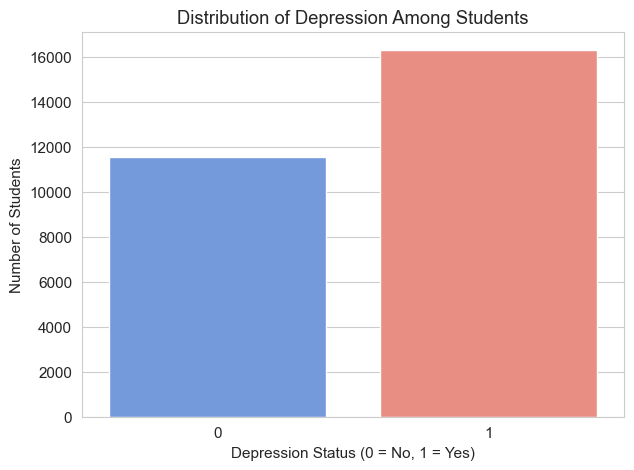

In [271]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Depression",
    hue="Depression",
    palette=["cornflowerblue", "salmon"],
    legend=False
)

plt.title("Distribution of Depression Among Students")
plt.xlabel("Depression Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Students")


plt.show()

Objective 2 – Studying Academic Pressure and Depression

In [272]:
print("Academic Pressure Distribution:")

print(df["Academic Pressure"].value_counts().sort_index())

Academic Pressure Distribution:
Academic Pressure
0.0       9
1.0    4799
2.0    4175
3.0    7448
4.0    5150
5.0    6286
Name: count, dtype: int64


Visualizing Academic Pressure and Depression

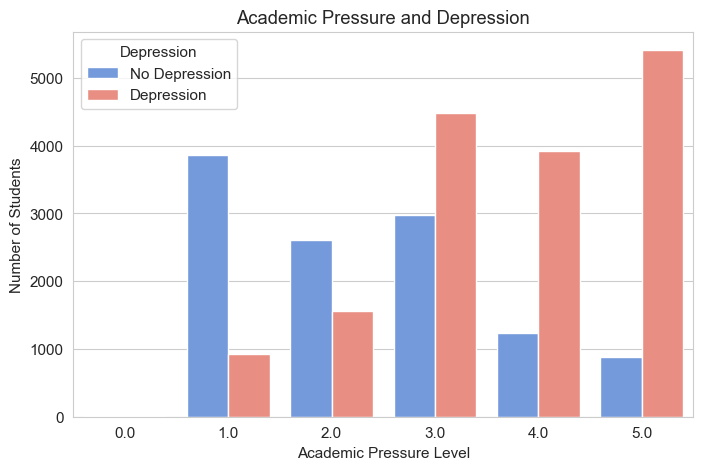

In [273]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Academic Pressure",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Academic Pressure and Depression")
plt.xlabel("Academic Pressure Level")
plt.ylabel("Number of Students")

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)


plt.show()

Percentage Analysis of Academic Pressure

Depression Percentage by Academic Pressure:
Depression             0      1
Academic Pressure              
0.0                55.56  44.44
1.0                80.58  19.42
2.0                62.54  37.46
3.0                39.90  60.10
4.0                23.86  76.14
5.0                13.94  86.06


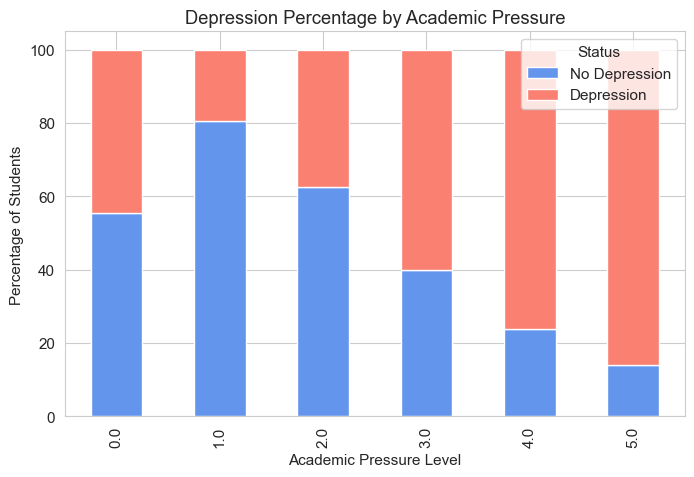

In [274]:
pressure_data = pd.crosstab(
    df["Academic Pressure"],
    df["Depression"],
    normalize="index"
) * 100

print("Depression Percentage by Academic Pressure:")

print(pressure_data.round(2))


pressure_data.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["cornflowerblue", "salmon"]
)

plt.title("Depression Percentage by Academic Pressure")
plt.xlabel("Academic Pressure Level")
plt.ylabel("Percentage of Students")

plt.legend(
    ["No Depression", "Depression"],
    title="Status"
)

plt.show()

 Objective 3 – Examining Lifestyle Habits

In [275]:
print("Sleep Duration Distribution:")

print(df["Sleep Duration"].value_counts())

Sleep Duration Distribution:
Sleep Duration
Less than 5 hours    8302
7-8 hours            7337
5-6 hours            6175
More than 8 hours    6035
Others                 18
Name: count, dtype: int64


Sleep Duration and Depression

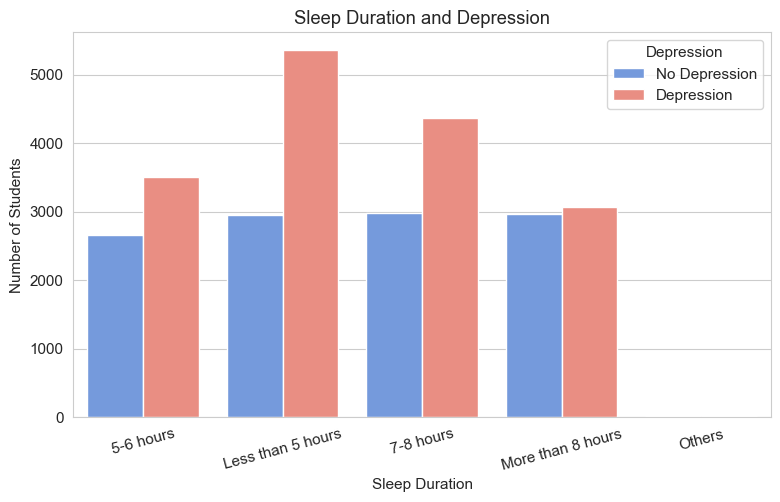

In [276]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Sleep Duration",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Sleep Duration and Depression")
plt.xlabel("Sleep Duration")
plt.ylabel("Number of Students")

plt.xticks(rotation=15)

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)



plt.show()

Dietary Habits and Depression

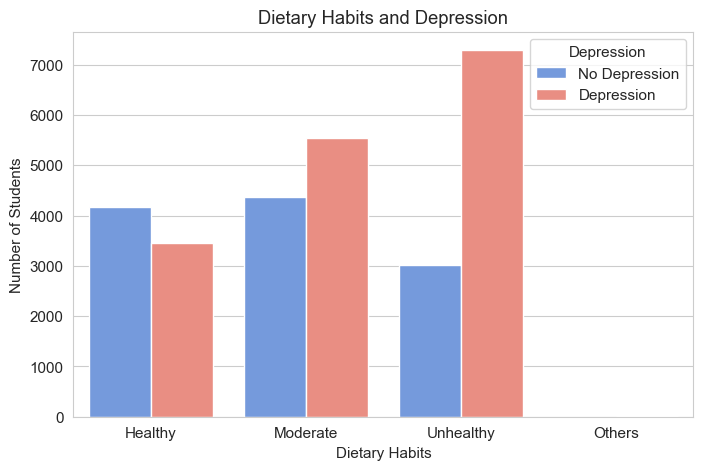

In [277]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Dietary Habits",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Dietary Habits and Depression")
plt.xlabel("Dietary Habits")
plt.ylabel("Number of Students")

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)

plt.show()

Percentage Analysis of Sleep Duration

Depression Percentage by Sleep Duration:
Depression             0      1
Sleep Duration                 
5-6 hours          43.13  56.87
7-8 hours          40.55  59.45
Less than 5 hours  35.51  64.49
More than 8 hours  49.13  50.87
Others             50.00  50.00


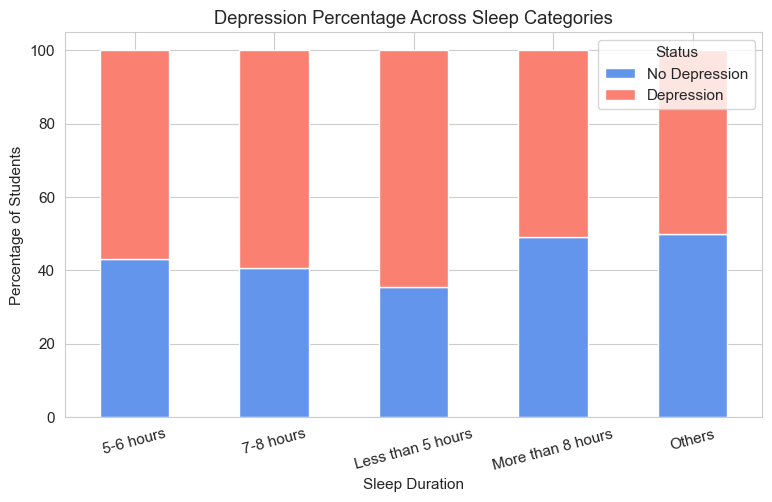

In [278]:
sleep_data = pd.crosstab(
    df["Sleep Duration"],
    df["Depression"],
    normalize="index"
) * 100

print("Depression Percentage by Sleep Duration:")

print(sleep_data.round(2))

sleep_data.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["cornflowerblue", "salmon"]
)

plt.title("Depression Percentage Across Sleep Categories")
plt.xlabel("Sleep Duration")
plt.ylabel("Percentage of Students")

plt.xticks(rotation=15)

plt.legend(
    ["No Depression", "Depression"],
    title="Status"
)

plt.show()

Objective 4 – Investigating Financial Stress

In [279]:
print("Financial Stress Distribution:")

print(df["Financial Stress"].value_counts().sort_index())

Financial Stress Distribution:
Financial Stress
1.0    5116
2.0    5058
3.0    5219
4.0    5770
5.0    6704
Name: count, dtype: int64


Financial Stress and Depression

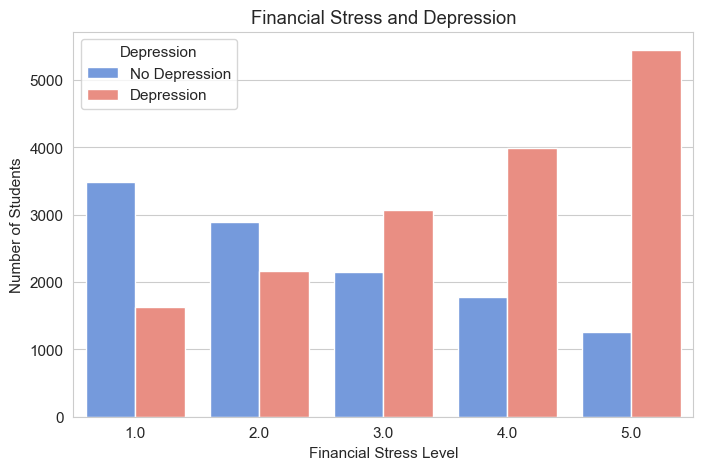

In [280]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Financial Stress",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Financial Stress and Depression")
plt.xlabel("Financial Stress Level")
plt.ylabel("Number of Students")

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)

plt.show()

Percentage Analysis of Financial Stress

Depression Percentage by Financial Stress:
Depression            0      1
Financial Stress              
1.0               68.18  31.82
2.0               57.06  42.94
3.0               41.10  58.90
4.0               30.92  69.08
5.0               18.75  81.25


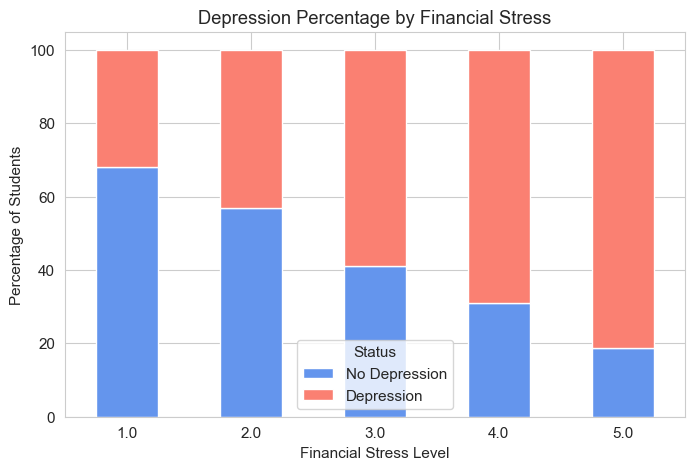

In [281]:
financial_data = pd.crosstab(
    df["Financial Stress"],
    df["Depression"],
    normalize="index"
) * 100

print("Depression Percentage by Financial Stress:")

print(financial_data.round(2))


financial_data.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5),
    color=["cornflowerblue", "salmon"]
)

plt.title("Depression Percentage by Financial Stress")
plt.xlabel("Financial Stress Level")
plt.ylabel("Percentage of Students")

plt.xticks(rotation=0)

plt.legend(
    ["No Depression", "Depression"],
    title="Status"
)

plt.show()

Objective 5 – Examining Academic Performance and Study Satisfaction

In [282]:
print("CGPA Statistics:")

print(df["CGPA"].describe())

CGPA Statistics:
count    27867.000000
mean         7.656084
std          1.470836
min          0.000000
25%          6.290000
50%          7.770000
75%          8.920000
max         10.000000
Name: CGPA, dtype: float64


Visualizing CGPA Distribution

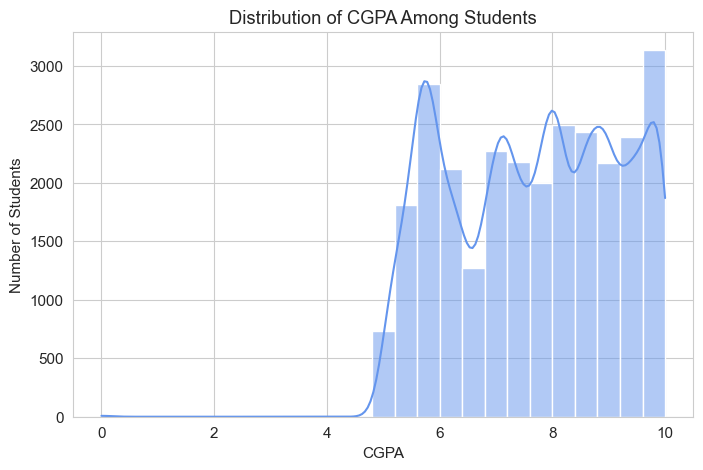

In [283]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="CGPA",
    bins=25,
    kde=True,
    color="cornflowerblue"
)

plt.title("Distribution of CGPA Among Students")
plt.xlabel("CGPA")
plt.ylabel("Number of Students")



plt.show()

Comparing CGPA Based on Depression Status

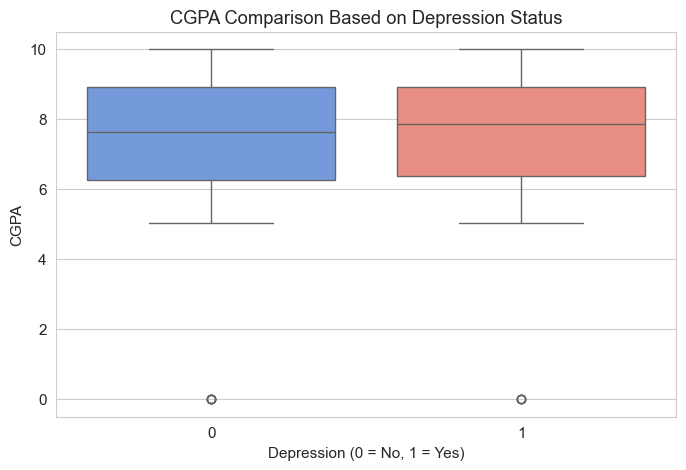

In [284]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="CGPA",
    hue="Depression",
    palette=["cornflowerblue", "salmon"],
    legend=False
)

plt.title("CGPA Comparison Based on Depression Status")
plt.xlabel("Depression (0 = No, 1 = Yes)")
plt.ylabel("CGPA")

plt.show()

Study Satisfaction and Depression

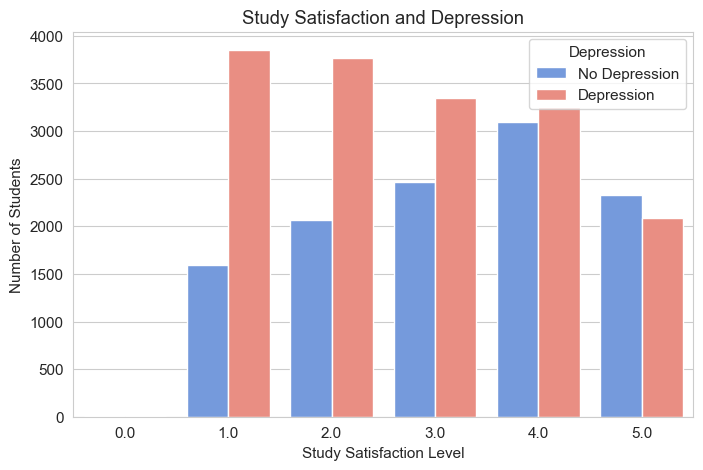

In [285]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Study Satisfaction",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Study Satisfaction and Depression")
plt.xlabel("Study Satisfaction Level")
plt.ylabel("Number of Students")

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)

plt.show()

Analysis – Work/Study Hours

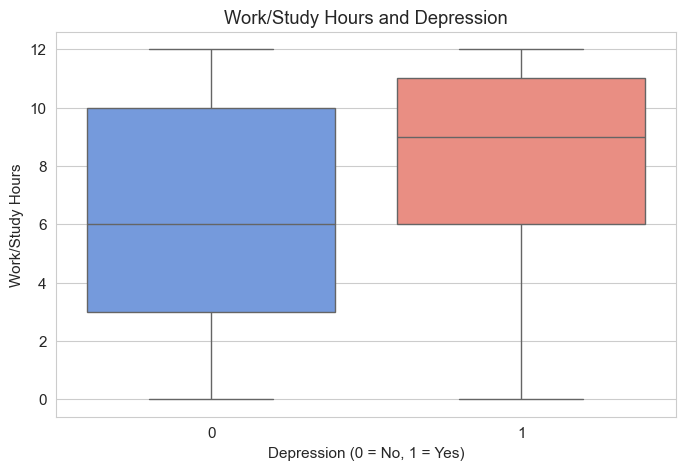

In [286]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Depression",
    y="Work/Study Hours",
    hue="Depression",
    palette=["cornflowerblue", "salmon"],
    legend=False
)

plt.title("Work/Study Hours and Depression")
plt.xlabel("Depression (0 = No, 1 = Yes)")
plt.ylabel("Work/Study Hours")

plt.show()

Analysis – Family History of Mental Illness

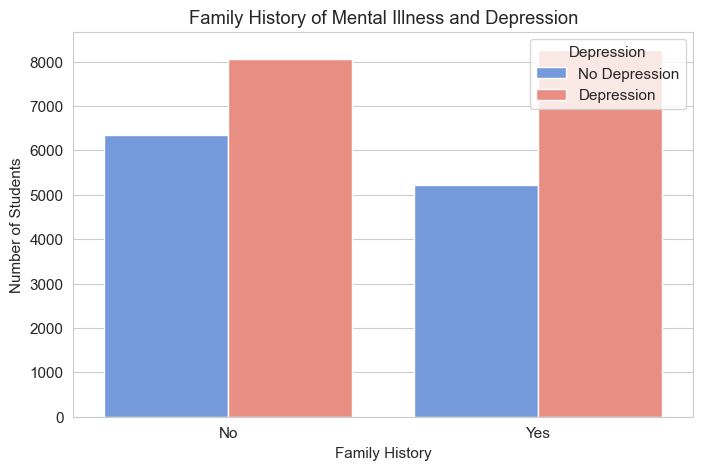

In [287]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Family History of Mental Illness",
    hue="Depression",
    palette=["cornflowerblue", "salmon"]
)

plt.title("Family History of Mental Illness and Depression")
plt.xlabel("Family History")
plt.ylabel("Number of Students")

plt.legend(
    title="Depression",
    labels=["No Depression", "Depression"]
)

plt.show()

Correlation Analysis of Numerical Features

Numerical Columns:
Index(['Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction',
       'Work/Study Hours', 'Financial Stress', 'Depression'],
      dtype='str')
Correlation Matrix:
                     Age  Academic Pressure  CGPA  Study Satisfaction  \
Age                 1.00              -0.08  0.01                0.01   
Academic Pressure  -0.08               1.00 -0.02               -0.11   
CGPA                0.01              -0.02  1.00               -0.04   
Study Satisfaction  0.01              -0.11 -0.04                1.00   
Work/Study Hours   -0.03               0.10  0.00               -0.04   
Financial Stress   -0.10               0.15  0.01               -0.07   
Depression         -0.23               0.47  0.02               -0.17   

                    Work/Study Hours  Financial Stress  Depression  
Age                            -0.03             -0.10       -0.23  
Academic Pressure               0.10              0.15        0.47  
CGPA                   

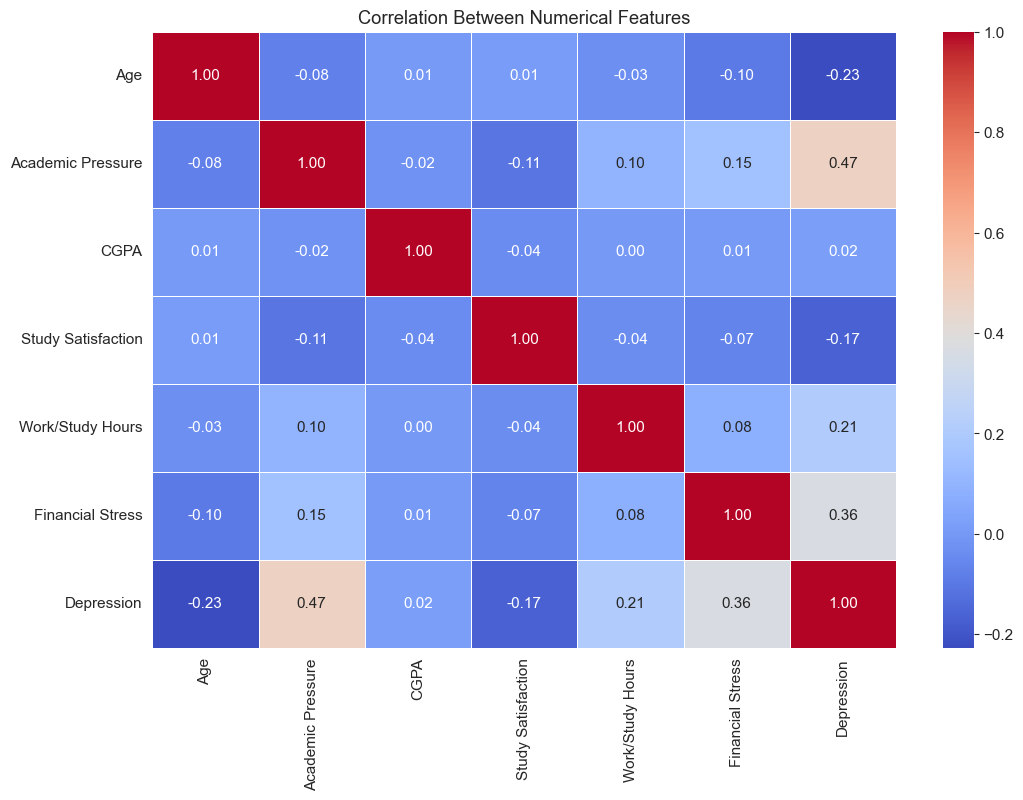

In [288]:
num_data = df.select_dtypes(
    include=["int64", "float64"]
)

print("Numerical Columns:")

print(num_data.columns)


correlation = num_data.corr()

print("Correlation Matrix:")

print(correlation.round(2))


plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Numerical Features")


plt.show()

Exploratory Data Analysis Summary

In [289]:
print("EXPLORATORY DATA ANALYSIS COMPLETED")

print("\nTotal Students Analysed:", df.shape[0])

print("\nTotal Features:", df.shape[1])

print("\nDepression Distribution:")

print(df["Depression"].value_counts())

print("\nAcademic Pressure Analysis:")

print(pressure_data.round(2))

print("\nSleep Duration Analysis:")

print(sleep_data.round(2))

print("\nFinancial Stress Analysis:")

print(financial_data.round(2))

print("\nAll EDA visualizations have been saved.")

EXPLORATORY DATA ANALYSIS COMPLETED

Total Students Analysed: 27867

Total Features: 14

Depression Distribution:
Depression
1    16307
0    11560
Name: count, dtype: int64

Academic Pressure Analysis:
Depression             0      1
Academic Pressure              
0.0                55.56  44.44
1.0                80.58  19.42
2.0                62.54  37.46
3.0                39.90  60.10
4.0                23.86  76.14
5.0                13.94  86.06

Sleep Duration Analysis:
Depression             0      1
Sleep Duration                 
5-6 hours          43.13  56.87
7-8 hours          40.55  59.45
Less than 5 hours  35.51  64.49
More than 8 hours  49.13  50.87
Others             50.00  50.00

Financial Stress Analysis:
Depression            0      1
Financial Stress              
1.0               68.18  31.82
2.0               57.06  42.94
3.0               41.10  58.90
4.0               30.92  69.08
5.0               18.75  81.25

All EDA visualizations have been saved.


Feature Engineering

In [290]:
print("Available Columns:")

print(df.columns.tolist())

print("\nNumerical Columns:")

print(df.select_dtypes(include=["int64", "float64"]).columns)

print("\nCategorical Columns:")

print(df.select_dtypes(include="object").columns)

Available Columns:
['Gender', 'Age', 'City', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression']

Numerical Columns:
Index(['Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction',
       'Work/Study Hours', 'Financial Stress', 'Depression'],
      dtype='str')

Categorical Columns:
Index(['Gender', 'City', 'Sleep Duration', 'Dietary Habits', 'Degree',
       'Have you ever had suicidal thoughts ?',
       'Family History of Mental Illness'],
      dtype='str')


C:\Users\91949\AppData\Local\Temp\ipykernel_14568\1382103716.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(df.select_dtypes(include="object").columns)


Feature 1 – Academic Pressure Category

In [291]:
def pressure_category(value):

    if value == 0:
        return "Not Specified"

    elif value <= 2:
        return "Low"

    elif value == 3:
        return "Moderate"

    else:
        return "High"


df["Academic_Pressure_Category"] = df["Academic Pressure"].apply(
    pressure_category
)

print("Academic Pressure Category Created")

print(df[["Academic Pressure",
          "Academic_Pressure_Category"]].head(10))

Academic Pressure Category Created
   Academic Pressure Academic_Pressure_Category
0                5.0                       High
1                2.0                        Low
2                3.0                   Moderate
3                3.0                   Moderate
4                4.0                       High
5                2.0                        Low
6                3.0                   Moderate
7                2.0                        Low
8                3.0                   Moderate
9                2.0                        Low


Feature 2 – Study Hours Category

In [292]:
def study_hours_category(hours):

    if hours <= 4:
        return "Low"

    elif hours <= 8:
        return "Moderate"

    elif hours <= 12:
        return "High"

    else:
        return "Very High"


df["Study_Hours_Category"] = df["Work/Study Hours"].apply(
    study_hours_category
)

print("Study Hours Category Created")

print(df[["Work/Study Hours",
          "Study_Hours_Category"]].head(10))

Study Hours Category Created
   Work/Study Hours Study_Hours_Category
0               3.0                  Low
1               3.0                  Low
2               9.0                 High
3               4.0                  Low
4               1.0                  Low
5               4.0                  Low
6               1.0                  Low
7               0.0                  Low
8              12.0                 High
9               2.0                  Low


Distribution of Newly Created Features

In [293]:
print("Academic Pressure Category Distribution:")

print(df["Academic_Pressure_Category"].value_counts())

print("\nStudy Hours Category Distribution:")

print(df["Study_Hours_Category"].value_counts())

Academic Pressure Category Distribution:
Academic_Pressure_Category
High             11436
Low               8974
Moderate          7448
Not Specified        9
Name: count, dtype: int64

Study Hours Category Distribution:
Study_Hours_Category
High        12309
Moderate     8047
Low          7511
Name: count, dtype: int64


Visualization of Academic Pressure Categories

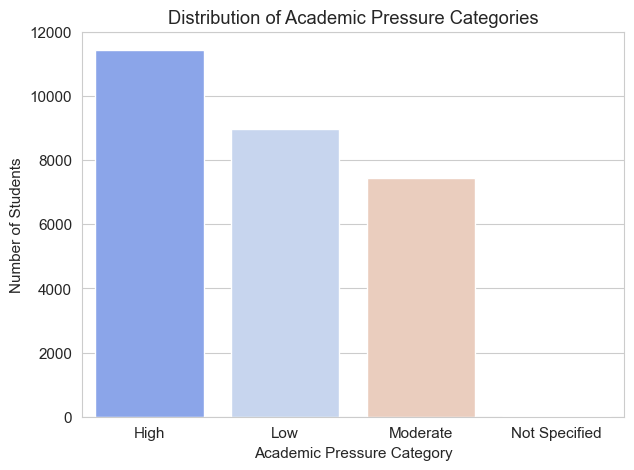

In [294]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Academic_Pressure_Category",
    hue="Academic_Pressure_Category",
    palette="coolwarm",
    legend=False
)

plt.title("Distribution of Academic Pressure Categories")
plt.xlabel("Academic Pressure Category")
plt.ylabel("Number of Students")

plt.show()

Visualization of Study Hours Categories

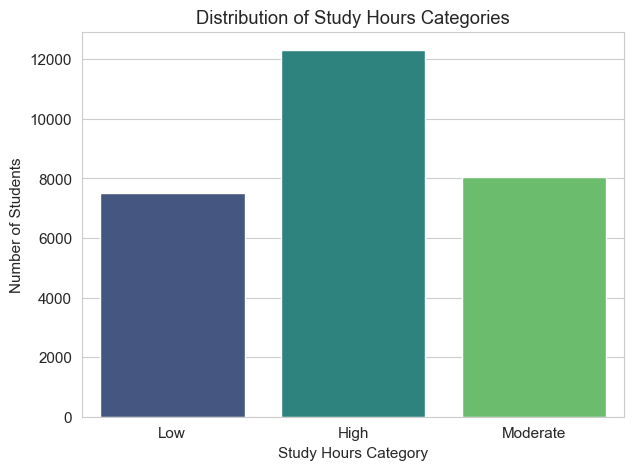

In [295]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Study_Hours_Category",
    hue="Study_Hours_Category",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Study Hours Categories")
plt.xlabel("Study Hours Category")
plt.ylabel("Number of Students")

plt.show()

Feature Selection

In [296]:
columns_to_drop = [
    "id",
    "City",
    "Profession",
    "Work Pressure",
    "Job Satisfaction",
    "Have you ever had suicidal thoughts ?"
]

df.drop(columns=columns_to_drop, inplace=True, errors="ignore")

print("Unnecessary Features Removed")
print("\nRemaining Columns:")
print(df.columns.tolist())
print("\nUpdated Dataset Shape:")
print(df.shape)

Unnecessary Features Removed

Remaining Columns:
['Gender', 'Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression', 'Academic_Pressure_Category', 'Study_Hours_Category']

Updated Dataset Shape:
(27867, 14)


Separating Independent and Dependent Variables

In [297]:
X = df.drop("Depression", axis=1)

y = df["Depression"]

print("Independent Variables:")

print(X.head())

print("\nDependent Variable:")

print(y.head())

Independent Variables:
   Gender   Age  Academic Pressure  CGPA  Study Satisfaction  \
0    Male  33.0                5.0  8.97                 2.0   
1  Female  24.0                2.0  5.90                 5.0   
2    Male  31.0                3.0  7.03                 5.0   
3  Female  28.0                3.0  5.59                 2.0   
4  Female  25.0                4.0  8.13                 3.0   

      Sleep Duration Dietary Habits   Degree  Work/Study Hours  \
0          5-6 hours        Healthy  B.Pharm               3.0   
1          5-6 hours       Moderate      BSc               3.0   
2  Less than 5 hours        Healthy       BA               9.0   
3          7-8 hours       Moderate      BCA               4.0   
4          5-6 hours       Moderate   M.Tech               1.0   

   Financial Stress Family History of Mental Illness  \
0               1.0                               No   
1               2.0                              Yes   
2               1.0        

Checking Input and Target Dimensions

In [298]:
print("Shape of X:")

print(X.shape)

print("\nShape of y:")

print(y.shape)

Shape of X:
(27867, 13)

Shape of y:
(27867,)


Identifying Feature Types

In [299]:
categorical_columns = X.select_dtypes(
    include="object"
).columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical Features:")

print(categorical_columns.tolist())

print("\nNumerical Features:")

print(numerical_columns.tolist())

Categorical Features:
['Gender', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Family History of Mental Illness', 'Academic_Pressure_Category', 'Study_Hours_Category']

Numerical Features:
['Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Work/Study Hours', 'Financial Stress']


C:\Users\91949\AppData\Local\Temp\ipykernel_14568\2049198617.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


Saving the Feature Engineered Dataset

In [300]:
df.to_csv(
    "../data/student_depression_featured.csv",
    index=False
)

print("Feature Engineered Dataset Saved Successfully")

Feature Engineered Dataset Saved Successfully


Feature Engineering Summary

In [301]:
print("FEATURE ENGINEERING COMPLETED")

print("\nTotal Records:")

print(df.shape[0])

print("\nTotal Features:")

print(df.shape[1] - 1)

print("\nTarget Variable:")

print("Depression")

print("\nMissing Values:")

print(df.isnull().sum())

print("\nDuplicate Records:")

print(df.duplicated().sum())

print("\nFinal Dataset:")

print(df.head())

FEATURE ENGINEERING COMPLETED

Total Records:
27867

Total Features:
13

Target Variable:
Depression

Missing Values:
Gender                              0
Age                                 0
Academic Pressure                   0
CGPA                                0
Study Satisfaction                  0
Sleep Duration                      0
Dietary Habits                      0
Degree                              0
Work/Study Hours                    0
Financial Stress                    0
Family History of Mental Illness    0
Depression                          0
Academic_Pressure_Category          0
Study_Hours_Category                0
dtype: int64

Duplicate Records:
0

Final Dataset:
   Gender   Age  Academic Pressure  CGPA  Study Satisfaction  \
0    Male  33.0                5.0  8.97                 2.0   
1  Female  24.0                2.0  5.90                 5.0   
2    Male  31.0                3.0  7.03                 5.0   
3  Female  28.0                3.0  5.59   

MACHINE LEARNING MODEL

Libraries

In [302]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score

Preparing Input Features and Target Variable

In [303]:
X = df.drop("Depression", axis=1)

X = X.drop(
    columns=["Academic Pressure", "Work/Study Hours"]
)

y = df["Depression"]

print("Independent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())

Independent Variables:
   Gender   Age  CGPA  Study Satisfaction     Sleep Duration Dietary Habits  \
0    Male  33.0  8.97                 2.0          5-6 hours        Healthy   
1  Female  24.0  5.90                 5.0          5-6 hours       Moderate   
2    Male  31.0  7.03                 5.0  Less than 5 hours        Healthy   
3  Female  28.0  5.59                 2.0          7-8 hours       Moderate   
4  Female  25.0  8.13                 3.0          5-6 hours       Moderate   

    Degree  Financial Stress Family History of Mental Illness  \
0  B.Pharm               1.0                               No   
1      BSc               2.0                              Yes   
2       BA               1.0                              Yes   
3      BCA               5.0                              Yes   
4   M.Tech               1.0                               No   

  Academic_Pressure_Category Study_Hours_Category  
0                       High                  Low  
1      

Splitting Data into Training and Testing sets

In [304]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:")
print(X_train.shape)

print("\nTesting Data Shape:")
print(X_test.shape)

Training Data Shape:
(22293, 11)

Testing Data Shape:
(5574, 11)


Label Encoding

In [305]:
le = LabelEncoder()

for col in categorical_columns:

    X_train[col] = le.fit_transform(X_train[col])

    X_test[col] = le.transform(X_test[col])

print("Categorical Values Converted Successfully")

print("\nTraining Data:")
print(X_train.head())

print("\nTesting Data:")
print(X_test.head())

Categorical Values Converted Successfully

Training Data:
       Gender   Age  CGPA  Study Satisfaction  Sleep Duration  Dietary Habits  \
23546       1  18.0  9.59                 3.0               2               1   
11976       0  32.0  7.88                 5.0               1               3   
10154       1  26.0  7.72                 4.0               2               0   
24595       1  33.0  5.84                 3.0               0               1   
3180        0  24.0  8.19                 2.0               1               1   

       Degree  Financial Stress  Family History of Mental Illness  \
23546      11               4.0                                 1   
11976      20               5.0                                 1   
10154      16               1.0                                 0   
24595       2               2.0                                 0   
3180       10               5.0                                 1   

       Academic_Pressure_Category  Study

StandardScaler

In [306]:
sc = StandardScaler()

X_train = sc.fit_transform(X_train)

X_test = sc.transform(X_test)

print("Feature Scaling Completed")

print("\nTraining Data Shape:")
print(X_train.shape)

print("\nTesting Data Shape:")
print(X_test.shape)

Feature Scaling Completed

Training Data Shape:
(22293, 11)

Testing Data Shape:
(5574, 11)


Model 1 – Logistic Regression

In [307]:
lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Logistic Regression Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_lr))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_lr))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_lr))

Logistic Regression Results

Accuracy: 0.7299964119124507

Confusion Matrix:
[[1436  876]
 [ 629 2633]]

Classification Report:
              precision    recall  f1-score   support

           0       0.70      0.62      0.66      2312
           1       0.75      0.81      0.78      3262

    accuracy                           0.73      5574
   macro avg       0.72      0.71      0.72      5574
weighted avg       0.73      0.73      0.73      5574



Model 2 – K-Nearest Neighbors (KNN)

In [308]:
knn = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean"
)

knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("KNN Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_knn))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_knn))

KNN Results

Accuracy: 0.753318980983136

Confusion Matrix:
[[1548  764]
 [ 611 2651]]

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.67      0.69      2312
           1       0.78      0.81      0.79      3262

    accuracy                           0.75      5574
   macro avg       0.75      0.74      0.74      5574
weighted avg       0.75      0.75      0.75      5574



Model 3 – Decision Tree

In [309]:
dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print("Decision Tree Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_dt))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_dt))

Decision Tree Results

Accuracy: 0.7050592034445641

Confusion Matrix:
[[1509  803]
 [ 841 2421]]

Classification Report:
              precision    recall  f1-score   support

           0       0.64      0.65      0.65      2312
           1       0.75      0.74      0.75      3262

    accuracy                           0.71      5574
   macro avg       0.70      0.70      0.70      5574
weighted avg       0.71      0.71      0.71      5574



Model 4 – Support Vector Machine (SVM)

In [310]:
svm_model = SVC(
    kernel="linear",
    random_state=42
)

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

print("SVM Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_svm))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_svm))

SVM Results

Accuracy: 0.7301758162899175

Confusion Matrix:
[[1450  862]
 [ 642 2620]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.63      0.66      2312
           1       0.75      0.80      0.78      3262

    accuracy                           0.73      5574
   macro avg       0.72      0.72      0.72      5574
weighted avg       0.73      0.73      0.73      5574



Model 5 – Random Forest

In [311]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Results")

print("\nAccuracy:",
      accuracy_score(y_test, y_pred_rf))

print("\nConfusion Matrix:")

print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")

print(classification_report(y_test, y_pred_rf))

Random Forest Results

Accuracy: 0.7852529601722282

Confusion Matrix:
[[1664  648]
 [ 549 2713]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.72      0.74      2312
           1       0.81      0.83      0.82      3262

    accuracy                           0.79      5574
   macro avg       0.78      0.78      0.78      5574
weighted avg       0.78      0.79      0.78      5574



Compare All Five Models

In [312]:
models = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
    "SVM",
    "Random Forest"
]

predictions = [
    y_pred_lr,
    y_pred_knn,
    y_pred_dt,
    y_pred_svm,
    y_pred_rf
]

accuracy = []
precision = []
recall = []
f1 = []

for pred in predictions:

    accuracy.append(accuracy_score(y_test, pred))

    precision.append(
        precision_score(y_test, pred, zero_division=0)
    )

    recall.append(
        recall_score(y_test, pred, zero_division=0)
    )

    f1.append(
        f1_score(y_test, pred, zero_division=0)
    )

results = pd.DataFrame({
    "Model": models,
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
})

print("MACHINE LEARNING MODEL COMPARISON")

print(results.round(4))

MACHINE LEARNING MODEL COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.7300     0.7504  0.8072    0.7777
1                  KNN    0.7533     0.7763  0.8127    0.7941
2        Decision Tree    0.7051     0.7509  0.7422    0.7465
3                  SVM    0.7302     0.7524  0.8032    0.7770
4        Random Forest    0.7853     0.8072  0.8317    0.8193


Visualize Model Comparison

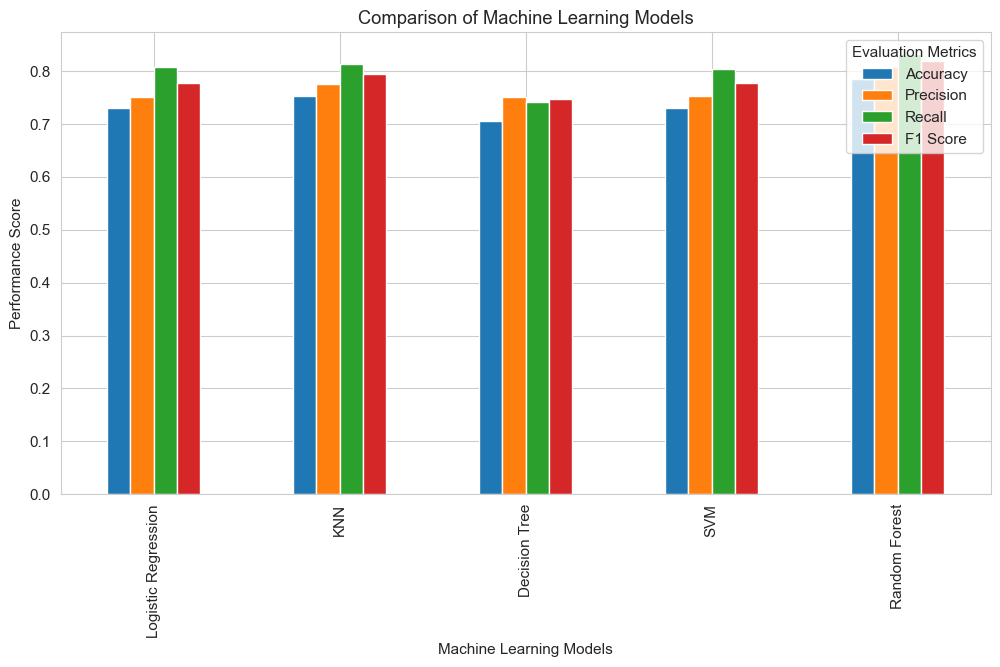

In [313]:
results.plot(
    x="Model",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")

plt.legend(title="Evaluation Metrics")

plt.show()

Identify the Best-Fit Model

In [314]:
best_model = results.loc[
    results["F1 Score"].idxmax()
]

print("BEST FIT MODEL")

print("\nModel Name:", best_model["Model"])

print("Accuracy:", best_model["Accuracy"])

print("Precision:", best_model["Precision"])

print("Recall:", best_model["Recall"])

print("F1 Score:", best_model["F1 Score"])

BEST FIT MODEL

Model Name: Random Forest
Accuracy: 0.7852529601722282
Precision: 0.8072002380243976
Recall: 0.831698344573881
F1 Score: 0.8192661935678696


Plot confusion matrices for all models

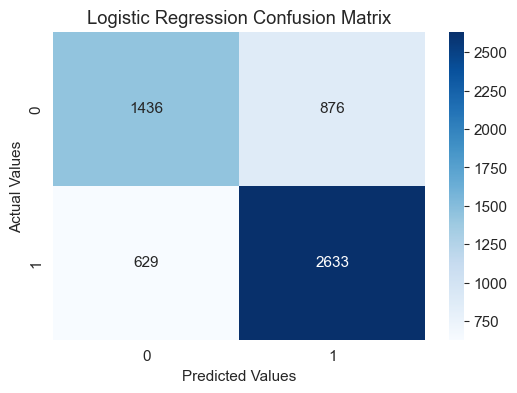

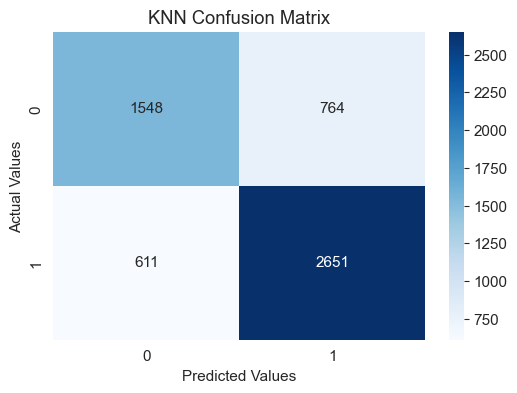

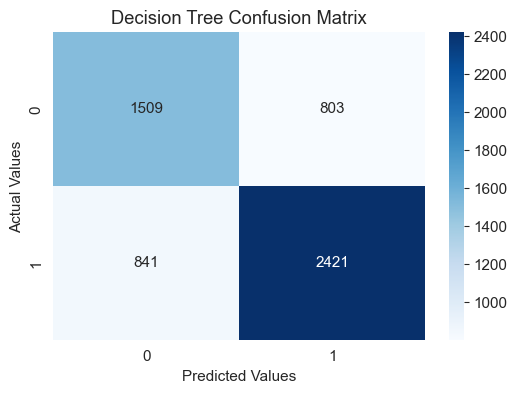

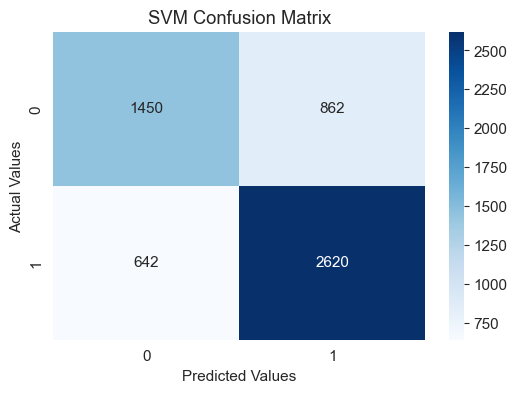

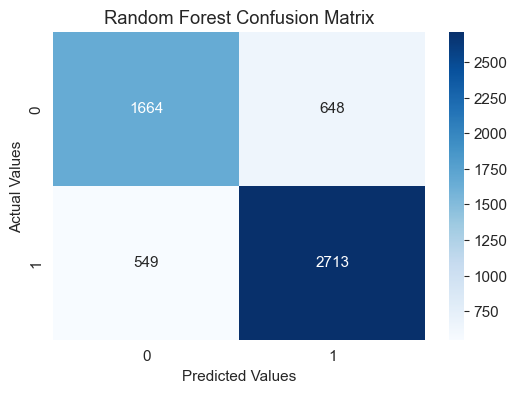

In [315]:
model_names = [
    "Logistic Regression",
    "KNN",
    "Decision Tree",
    "SVM",
    "Random Forest"
]

for name, pred in zip(model_names, predictions):

    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(name + " Confusion Matrix")

    plt.xlabel("Predicted Values")

    plt.ylabel("Actual Values")

    plt.show()